# Concessions Pricing Challenge: analysis notebook

Blessing Masanga, Daniel Youngquist, Zeynep Bastas · Case Western Reserve University

This notebook builds our 5 event groups, forecasts the 9 upcoming shows, sets our price card and writes
the two CSV files we submitted (event_groups.csv and upcoming_forecast.csv).

**How to run in Colab:** Runtime > Run all. When the first code cell asks, upload the 8 CSV files from the
challenge email (or put them in a Drive folder and point `DATA_DIR` at it). Section 9 saves both CSVs to an
`outputs` folder.

1. Load and join the 8 files
2. Spend per head for every past show
3. The spend map and our 5 groups
4. What the audience data adds
5. What each group actually paid
6. Grouping options, backtested
7. The 9 upcoming shows: group and attendance (low / base / high)
8. Forecast at our price card
9. Write the two submission CSVs
10. Price scenario helper
11. Other methods we tried
12. A second script, compared

## 1. Load and join the 8 files

In [1]:
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 2)

DATA_DIR = "data"   # or a Drive folder, e.g. "/content/drive/MyDrive/Cavs Hackathon/data"
NEEDED = ["historical_events", "upcoming_events", "performer_demographic_profile", "performer_demographic_meta",
          "concessions_top5_overall_items", "concessions_top5_overall_by_event", "concessions_top5_by_event",
          "concessions_category_by_event"]

def find_files(folder):
    """Match files by name, ignoring download prefixes like 'a6fa6f85-' and Colab's ' (1)' suffix."""
    found = {}
    for path in glob.glob(os.path.join(folder, "*.csv")):
        base = re.sub(r" \(\d+\)", "", os.path.basename(path))
        for name in NEEDED:
            if base == f"{name}.csv" or base.endswith(f"-{name}.csv"):
                found[name] = path
    return found

files_found = find_files(DATA_DIR) if os.path.isdir(DATA_DIR) else {}
if len(files_found) < len(NEEDED):
    try:
        from google.colab import files as colab_files
        os.makedirs(DATA_DIR, exist_ok=True)
        print("Upload the 8 CSV files from the Cavs email:")
        for fname, content in colab_files.upload().items():
            with open(os.path.join(DATA_DIR, fname), "wb") as f:
                f.write(content)
        files_found = find_files(DATA_DIR)
    except ImportError:
        pass
missing = [n for n in NEEDED if n not in files_found]
assert not missing, f"Missing files: {missing}. Put them in {DATA_DIR!r} and run again."
d = {name: pd.read_csv(path) for name, path in files_found.items()}
print("Loaded:", {k: len(v) for k, v in d.items()})

Loaded: {'concessions_top5_by_event': 180, 'concessions_top5_overall_by_event': 180, 'concessions_top5_overall_items': 5, 'historical_events': 36, 'concessions_category_by_event': 108, 'performer_demographic_meta': 31, 'upcoming_events': 9, 'performer_demographic_profile': 1047}


In [2]:
ITEMS = {"20oz Dasani Water": "water", "Double Cocktail": "cocktail", "24oz Fountain Drink": "fountain",
         "Bavarian Pretzel": "pretzel", "16oz Michelob Ultra": "michelob"}
ITEM_ORDER = ["water", "cocktail", "fountain", "pretzel", "michelob"]
CATS = {"Alcoholic Beverages": "alc", "Food": "food", "NA Beverage": "nabev"}
PRICE_NOW = (d["concessions_top5_overall_items"].assign(item=lambda t: t.item_name.map(ITEMS))
             .set_index("item")["current_price"].to_dict())

def audience_shares(d):
    """One row per performer. Each dimension is divided by its own total, as the prompt says."""
    p = d["performer_demographic_profile"].copy()
    p["share"] = p.buyer_count / p.groupby(["performer_id", "dimension"]).buyer_count.transform("sum")
    wide = p.pivot_table(index="performer_id", columns=["dimension", "value"], values="share", fill_value=0.0)
    s = lambda dim, vals: sum(wide.get((dim, v), 0.0) for v in vals)
    out = pd.DataFrame(index=wide.index)
    out["pct_female"] = s("gender", ["F"])
    out["pct_age_u35"] = s("age_bucket", ["<25", "25-34"])
    out["pct_age_55plus"] = s("age_bucket", ["55-64", "65+"])
    out["pct_kids"] = s("has_children", ["Yes"])
    out["pct_married"] = s("marital_status", ["M"])
    out["pct_homeowner"] = s("home_ownership", ["HOME OWNER"])
    out["pct_income_100k_plus"] = s("income", ["$101K - $250K", "$251K - $500K", "$501K - $1M", ">$1M"])
    out["bar_score"] = (1 - out.pct_female) + out.pct_age_55plus - out.pct_age_u35   # used by option B only
    return out.reset_index().merge(d["performer_demographic_meta"], on="performer_id", how="left")

def build_historical(d):
    m = d["historical_events"].copy()
    m["avg_ticket_price"] = m.ticket_revenue / m.tickets_sold
    cat = d["concessions_category_by_event"].assign(cat=lambda t: t.category.map(CATS))
    cw = cat.pivot_table(index="event_id", columns="cat", values=["units_sold", "gross_sales"], aggfunc="sum")
    cw.columns = [f"{c}_{'units' if v == 'units_sold' else 'gross'}" for v, c in cw.columns]
    t5 = d["concessions_top5_overall_by_event"].assign(item=lambda t: t.item_name.map(ITEMS))
    iw = t5.pivot_table(index="event_id", columns="item", values=["units_sold", "gross_sales"], aggfunc="sum")
    iw.columns = [f"{i}_{'units' if v == 'units_sold' else 'gross'}" for v, i in iw.columns]
    m = m.merge(cw.reset_index(), on="event_id").merge(iw.reset_index(), on="event_id")
    n = m.tickets_sold
    for c in CATS.values():
        m[f"{c}_gross_pc"] = m[f"{c}_gross"] / n                 # dollars per ticket sold
        m[f"{c}_units_pc"] = m[f"{c}_units"] / n                 # units per ticket sold
    m["conc_gross_pc"] = m[[f"{c}_gross" for c in CATS.values()]].sum(axis=1) / n
    for i in ITEM_ORDER:
        m[f"{i}_per1k"] = 1000 * m[f"{i}_units"] / n             # units per 1,000 tickets
        m[f"{i}_price"] = m[f"{i}_gross"] / m[f"{i}_units"]      # what guests actually paid on average
    m = m.merge(audience_shares(d), on="performer_id", how="left")
    m["daytime"] = m.time_of_day.isin(["Morning", "Afternoon"])
    m["weekend"] = m.day_of_week.isin(["Friday", "Saturday", "Sunday"])
    return m

def build_upcoming(d):
    u = d["upcoming_events"].merge(audience_shares(d), on="performer_id", how="left")
    u["daytime"] = u.time_of_day.isin(["Morning", "Afternoon"])
    u["weekend"] = u.day_of_week.isin(["Friday", "Saturday", "Sunday"])
    u["has_history"] = u.performer_id.isin(d["historical_events"].performer_id)
    return u

m, up = build_historical(d), build_upcoming(d)

# checks: one row per show, and the per-show units add up to the overall top-5 file
assert m.event_id.is_unique and len(m) == 36
per_show = d["concessions_top5_overall_by_event"].groupby("item_name").units_sold.sum()
overall = d["concessions_top5_overall_items"].set_index("item_name").total_units_sold
assert (per_show.reindex(overall.index) == overall).all()
print("Joined:", m.shape, "| shows without audience data:", m.loc[m.buyers_with_demos.isna(), "event_id"].tolist())

Joined: (36, 54) | shows without audience data: ['E101']


## 2. Spend per head for every past show

Crowds differ a lot in size, so we compare **dollars per ticket sold** and **units per 1,000 tickets**.

In [3]:
cols = ["event_id", "performer_id", "event_type", "genre", "day_of_week", "time_of_day", "tickets_sold",
        "conc_gross_pc", "alc_gross_pc", "food_gross_pc", "nabev_gross_pc"] + [f"{i}_per1k" for i in ITEM_ORDER]
m[cols].sort_values("alc_gross_pc", ascending=False).round(1)

,event_id,performer_id,event_type,genre,day_of_week,time_of_day,tickets_sold,conc_gross_pc,alc_gross_pc,food_gross_pc,nabev_gross_pc,water_per1k,cocktail_per1k,fountain_per1k,pretzel_per1k,michelob_per1k
7,E112,P30,Concert,Country,Saturday,Evening,11552,23.6,19.6,2.3,1.6,136.1,96.5,39.6,46.2,126.9
2,E104,P14,Concert,Rock,Tuesday,Evening,6358,23.8,17.3,3.9,2.6,171.4,89.8,65.6,55.7,144.5
26,E140,P31,Concert,Rock,Thursday,Evening,6677,20.8,15.6,2.6,2.5,163.4,83.0,68.0,52.7,81.6
28,E143,P21,Concert,Rock,Thursday,Evening,13835,19.3,15.3,2.1,2.0,200.5,96.7,34.0,43.9,80.4
23,E135,P09,Concert,Rock,Saturday,Evening,9133,18.5,14.3,2.1,2.1,192.8,103.8,45.1,47.6,99.3
14,E122,P15,Concert,Rock,Friday,Evening,18286,15.5,12.7,1.3,1.4,151.5,82.5,29.0,28.1,66.7
21,E132,P02,Concert,Rock,Thursday,Evening,12657,17.0,12.7,2.5,1.8,181.0,108.0,31.0,35.2,62.3
8,E113,P32,Concert,Hip-Hop / R&B,Saturday,Evening,4707,17.1,12.4,3.2,1.5,107.5,109.8,55.0,29.7,9.6
27,E141,P22,Concert,Hip-Hop / R&B,Saturday,Evening,16048,14.2,10.9,1.7,1.6,128.5,72.1,38.4,27.8,30.5
10,E116,P06,Concert,Pop,Tuesday,Evening,12593,15.2,10.8,2.4,2.0,163.6,55.3,52.8,38.7,30.8


## 3. The spend map and our 5 groups

Rules, in order (stop at the first yes): sports event, or a family show where at least half the buyers are men =
**Family Night & Sports**; any other family show = **Family Day**; rock or country concert = **Bar**;
pop concert = **Pop**; everything else (hip-hop/R&B, comedy) = **Social**.

We started with 4 groups (pop inside Social). Separate checks by all three of us pointed to giving pop its own
group, and the backtest in section 6 agrees: pop crowds spend about the same per fan, but less of it on alcohol.

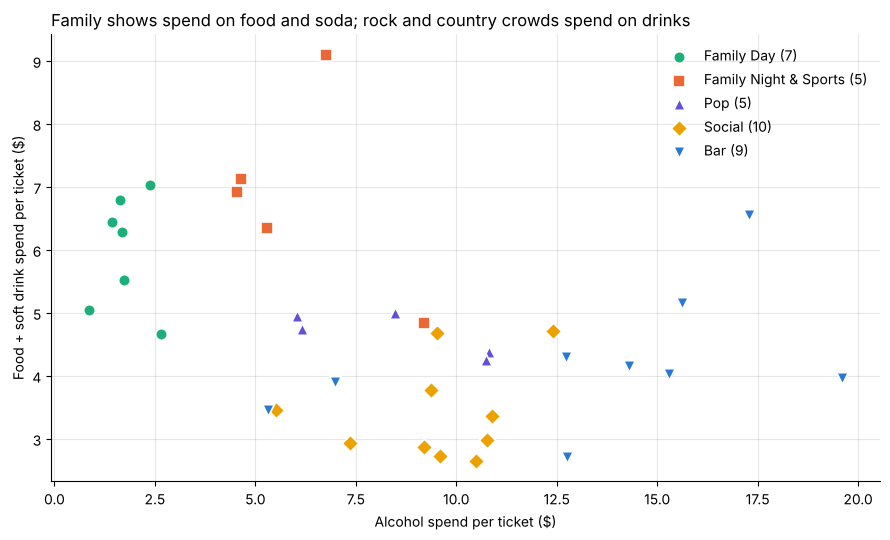

,shows,alcohol_per_head,spend_per_head,water_per1k,cocktail_per1k,fountain_per1k,pretzel_per1k,michelob_per1k
group,,,,,,,,
Family Day,7,1.8,7.7,94.9,10.0,71.3,60.7,10.5
Family Night & Sports,5,6.1,12.9,117.6,29.7,80.7,61.0,41.8
Pop,5,8.5,13.1,167.8,48.5,58.0,46.1,27.0
Social,10,9.5,12.9,114.4,71.5,36.7,29.5,29.4
Bar,9,13.3,17.6,162.7,82.1,43.5,42.5,79.7


In [4]:
GROUP_ORDER = ["Family Day", "Family Night & Sports", "Pop", "Social", "Bar"]

def show_group(df):
    """Our 5 groups: family shows split by the male share of buyers, then genre for adult shows.
    A family show with no buyer data counts as not mostly male, so it lands in Family Day."""
    family = df.event_type.eq("Family")
    male_heavy = (1 - df.pct_female) >= 0.5
    concert = df.event_type.eq("Concert")
    rock_country = concert & df.genre.isin(["Rock", "Country"])
    pop = concert & df.genre.eq("Pop")
    return np.select([df.event_type.eq("Sports") | (family & male_heavy), family, rock_country, pop],
                     ["Family Night & Sports", "Family Day", "Bar", "Pop"], default="Social")

m["group"], up["group"] = show_group(m), show_group(up)

colors = {"Family Day": "#1baf7a", "Family Night & Sports": "#eb6834", "Pop": "#6250d6", "Social": "#eda100", "Bar": "#2a78d6"}
markers = {"Family Day": "o", "Family Night & Sports": "s", "Pop": "^", "Social": "D", "Bar": "v"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in GROUP_ORDER:
    s = m[m.group == t]
    ax.scatter(s.alc_gross_pc, s.food_gross_pc + s.nabev_gross_pc, s=70, color=colors[t], marker=markers[t],
               edgecolor="white", linewidth=1.2, label=f"{t} ({len(s)})", zorder=3)
ax.set_xlabel("Alcohol spend per ticket ($)")
ax.set_ylabel("Food + soft drink spend per ticket ($)")
ax.set_title("Family shows spend on food and soda; rock and country crowds spend on drinks", loc="left")
ax.grid(alpha=0.3); ax.legend(frameon=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

profile = m.groupby("group").agg(shows=("event_id", "count"), alcohol_per_head=("alc_gross_pc", "mean"),
                                 spend_per_head=("conc_gross_pc", "mean"),
                                 **{f"{i}_per1k": (f"{i}_per1k", "mean") for i in ITEM_ORDER})
profile.loc[GROUP_ORDER].round(1)

## 4. What the audience data adds

Spearman rank correlations, adult evening shows only (concerts + comedy). `*` = p < 0.05. Small sample, so
read these as directions, not laws.

In [5]:
adult = m[m.event_type.isin(["Concert", "Comedy"]) & m.buyers_with_demos.notna()]
traits = ["pct_female", "pct_age_u35", "pct_age_55plus", "pct_married", "pct_homeowner", "pct_income_100k_plus"]
targets = ["alc_gross_pc"] + [f"{i}_per1k" for i in ITEM_ORDER]
table = {}
for t in targets:
    table[t] = {c: (lambda r: f"{r[0]:+.2f}{'*' if r[1] < 0.05 else ''}")(stats.spearmanr(adult[c], adult[t]))
                for c in traits}
print(f"n = {len(adult)} adult shows")
pd.DataFrame(table)

n = 24 adult shows


,alc_gross_pc,water_per1k,cocktail_per1k,fountain_per1k,pretzel_per1k,michelob_per1k
pct_female,-0.56*,-0.20,-0.54*,+0.40,-0.05,-0.73*
pct_age_u35,-0.39,+0.07,-0.75*,+0.40,+0.19,-0.39
pct_age_55plus,+0.29,+0.11,+0.48*,-0.47*,-0.05,+0.54*
pct_married,+0.35,+0.50*,+0.39,-0.32,+0.38,+0.65*
pct_homeowner,+0.35,+0.14,+0.48*,-0.53*,+0.09,+0.63*
pct_income_100k_plus,+0.28,+0.37,+0.28,-0.48*,+0.21,+0.52*


## 5. What each group actually paid

Average price paid = gross sales / units. The menu price (max_item_price) was the same at every past show, yet
family crowds paid about 7% to 25% less on average, so they must get deals (bundles, promos or cheaper stands).
Worth asking the Cavs.

In [6]:
paid = pd.DataFrame({g: {i: m[m.group == g][f"{i}_gross"].sum() / m[m.group == g][f"{i}_units"].sum()
                         for i in ITEM_ORDER} for g in GROUP_ORDER}).T
paid.loc["Current menu"] = [PRICE_NOW[i] for i in ITEM_ORDER]
paid.round(2)

,water,cocktail,fountain,pretzel,michelob
Family Day,5.19,22.68,7.18,8.10,12.57
Family Night & Sports,5.15,22.91,7.06,7.98,12.70
Pop,5.75,28.27,7.79,10.59,16.65
Social,5.71,28.23,7.73,10.47,16.60
Bar,5.72,28.32,7.73,10.43,16.65
Current menu,5.62,28.79,7.79,10.59,16.99


## 6. Grouping options, backtested

To mimic a brand-new performer, we hide all shows by one performer, compute each group's average units per
ticket from the remaining shows, and forecast the hidden shows from their group. Error = units missed / units
sold, using actual attendance (lower is better).

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

Y = np.log(m[[f"{i}_per1k" for i in ITEM_ORDER]].values / 1000)   # log units per ticket
ATT, PERF = m.tickets_sold.values, m.performer_id.values

def error_pct(P):
    act, pred = np.exp(Y) * ATT[:, None], np.exp(P) * ATT[:, None]
    return 100 * np.abs(pred - act).sum() / act.sum()

def leave_performer_out(labels):
    P = np.zeros_like(Y)
    for p in np.unique(PERF):
        test = PERF == p
        for i in np.where(test)[0]:
            same = ~test & (labels == labels[i])
            P[i] = Y[same].mean(0) if same.any() else Y[~test].mean(0)
    return P

def opt_e(df): return np.where(df.event_type.eq("Family") | df.daytime, "family/day", "adult evening")
def opt_a(df): return (df.event_type + np.where(df.daytime, " day", " evening")).values
def opt_d(df):
    g = np.where(df.event_type.eq("Concert"), df.genre.replace({"Country": "Rock"}), df.event_type)
    return np.where(df.event_type.eq("Family"), np.where(df.daytime, "Family day", "Family evening"), g)
def opt_t4(df):
    family = df.event_type.eq("Family")
    rock_country = df.event_type.eq("Concert") & df.genre.isin(["Rock", "Country"])
    return np.select([family & df.daytime, family | df.event_type.eq("Sports"), rock_country],
                     ["Family Day", "Family Night", "Bar"], default="Social")
def opt_b(df, cut=0.45):
    fam = df.event_type.eq("Family") | df.daytime
    return np.select([df.event_type.eq("Sports") | (fam & (df.pct_female <= 0.5)), fam, df.bar_score >= cut],
                     ["Family Night & Sports", "Family Day", "Bar Crowd"], default="Mixed Crowd")

def opt_first_pick(df):
    """Our first pick: the same rules, but pop stays inside Social (4 groups)."""
    g = show_group(df)
    return np.where(g == "Pop", "Social", g)
def opt_f(df):
    """Genre tiers: Family / Rock & Country / Pop / hip-hop, comedy & sports."""
    concert = df.event_type.eq("Concert")
    return np.select([df.event_type.eq("Family"), concert & df.genre.isin(["Rock", "Country"]), concert & df.genre.eq("Pop")],
                     ["Family", "Rock & Country", "Pop"], default="Hip-hop, comedy & sports")

def option_c():
    """k-means on what shows bought, then a small tree places held-out shows from pre-show facts."""
    X_km = np.log(m[[f"{i}_per1k" for i in ITEM_ORDER] + ["alc_units_pc", "food_units_pc", "nabev_units_pc"]].values)
    pre = ["is_family", "is_sports", "is_comedy", "daytime", "weekend", "pct_female", "pct_age_u35",
           "pct_age_55plus", "pct_married", "pct_homeowner", "pct_income_100k_plus", "bar_score"]
    X_pre = m.assign(is_family=m.event_type.eq("Family"), is_sports=m.event_type.eq("Sports"),
                     is_comedy=m.event_type.eq("Comedy"))[pre].astype(float).values   # trees accept the one NaN row (E101)
    P = np.zeros_like(Y)
    for p in np.unique(PERF):
        test = PERF == p; tr = ~test
        sc = StandardScaler().fit(X_km[tr])
        km = KMeans(4, n_init=50, random_state=0).fit(sc.transform(X_km[tr]))
        tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=0).fit(X_pre[tr], km.labels_)
        means = np.array([Y[tr][km.labels_ == c].mean(0) for c in range(4)])
        P[test] = means[tree.predict(X_pre[test])]
    return P

results = {"No groups": leave_performer_out(np.array(["all"] * len(m))),
           "C. Clusters": option_c(),
           "E. Family vs adult": leave_performer_out(opt_e(m)),
           "A. Format": leave_performer_out(opt_a(m)),
           "B. Crowd type": leave_performer_out(opt_b(m)),
           "T4. Show tiers": leave_performer_out(opt_t4(m)),
           "B+. First pick (4 groups)": leave_performer_out(opt_first_pick(m)),
           "F. Genre tiers (4 groups)": leave_performer_out(opt_f(m)),
           "D. Genre": leave_performer_out(opt_d(m)),
           "Our pick: B+ with Pop (5 groups)": leave_performer_out(m.group.values)}
pd.Series({k: round(error_pct(v), 1) for k, v in results.items()}, name="error %").to_frame()

,error %
No groups,34.0
C. Clusters,28.4
E. Family vs adult,27.3
A. Format,27.3
B. Crowd type,24.9
T4. Show tiers,24.6
B+. First pick (4 groups),24.0
F. Genre tiers (4 groups),23.5
D. Genre,23.6
Our pick: B+ with Pop (5 groups),21.8


Is the Pop split a real gain or luck? We resample performers 4,000 times and compare the two versions on each
resample. If the gain held up in only about half of them, it would be noise.

In [8]:
rng = np.random.default_rng(7)
first, ours = results["B+. First pick (4 groups)"], results["Our pick: B+ with Pop (5 groups)"]
def error_on(P, idx):
    act, pred = np.exp(Y[idx]) * ATT[idx, None], np.exp(P[idx]) * ATT[idx, None]
    return 100 * np.abs(pred - act).sum() / act.sum()
perfs = np.unique(PERF)
diffs = np.array([error_on(ours, idx) - error_on(first, idx)
                  for idx in (np.concatenate([np.where(PERF == p)[0] for p in rng.choice(perfs, len(perfs))])
                              for _ in range(4000))])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Pop split vs first pick: {diffs.mean():+.1f} points (95% interval {lo:+.1f} to {hi:+.1f}); "
      f"better in {np.mean(diffs < 0):.0%} of resamples")

Pop split vs first pick: -2.2 points (95% interval -4.8 to -0.1); better in 98% of resamples


## 7. The 9 upcoming shows: group and attendance rules

Final attendance is the biggest open assumption. Rule 1 = to date x 1.25. Rule 2 = repeat acts get the larger of
to date x 1.10 and their last attendance (x 0.76 for a weekend-to-weekday move, split across same-day shows);
new acts get to date x 1.25. Rule 3 = like Rule 2, but new acts use their genre's past median.

**Our pick:** Rule 2 is the base case. High = the largest of the three rules. Low = the smallest, except for repeat
acts: 75% of their past crowd (the weakest repeat show in our data), never below tickets already sold.

In [9]:
eve_concerts = m[(m.time_of_day == "Evening") & (m.event_type == "Concert")]
med = eve_concerts.groupby("weekend").tickets_sold.median()
WEEKDAY = med[False] / med[True]
genre_median = m.groupby("genre").tickets_sold.median()
last = m.sort_values("event_id").groupby("performer_id").last()

same_day = up.groupby(["performer_id", "month_code", "day_of_week"]).event_id.transform("count")
base = up.performer_id.map(last.tickets_sold).fillna(up.genre.map(genre_median))
slot = np.where(~up.weekend & up.performer_id.map(last.weekend).fillna(True).astype(bool), WEEKDAY, 1.0)
anchor = base * slot / same_day
to_date = up.tickets_sold_to_date
up["rule1"] = (to_date * 1.25).round(-1)
up["rule2"] = np.where(up.has_history, np.maximum(to_date * 1.10, anchor), to_date * 1.25).round(-1)
up["rule3"] = np.maximum(to_date * 1.10, anchor).round(-1)
up["last_visit"] = up.performer_id.map(lambda p: f"{last.loc[p, 'event_id']}: {last.loc[p, 'tickets_sold']:,}"
                                       if p in last.index else "first visit")
repeat = m.groupby("performer_id").tickets_sold.agg(["count", "min", "mean"]).query("count > 1")
LOW_FACTOR = (repeat["min"] / repeat["mean"]).min()   # weakest repeat show vs that act's average (P25)
up["att_base"] = up.rule2
up["att_low"] = np.where(up.has_history, np.maximum(to_date, LOW_FACTOR * anchor).round(),
                         up[["rule1", "rule2", "rule3"]].min(axis=1))
up["att_high"] = up[["rule1", "rule2", "rule3"]].max(axis=1)
print(f"weekday / weekend median attendance (evening concerts): {WEEKDAY:.2f} | low factor for repeat acts: {LOW_FACTOR:.2f}")
print("Total people, low / base / high:", int(up.att_low.sum()), int(up.att_base.sum()), int(up.att_high.sum()))
up[["event_id", "performer_id", "event_type", "genre", "day_of_week", "time_of_day", "tickets_sold_to_date",
    "last_visit", "group", "rule1", "rule2", "rule3", "att_low", "att_base", "att_high"]]

weekday / weekend median attendance (evening concerts): 0.76 | low factor for repeat acts: 0.75
Total people, low / base / high: 54363 62740 75370


,event_id,performer_id,event_type,genre,day_of_week,time_of_day,tickets_sold_to_date,last_visit,group,rule1,rule2,rule3,att_low,att_base,att_high
0,E109,P33,Family,Sports,Friday,Evening,518,"E130: 8,833",Family Day,650.0,8830.0,8830.0,6651.0,8830.0,8830.0
1,E110,P26,Concert,Rock,Thursday,Evening,8081,first visit,Bar,10100.0,10100.0,8890.0,8890.0,10100.0,10100.0
2,E111,P03,Family,Sports,Wednesday,Evening,506,"E124: 5,658",Family Day,630.0,4300.0,4300.0,3240.0,4300.0,4300.0
3,E115,P23,Concert,Pop,Friday,Evening,8006,first visit,Pop,10010.0,10010.0,12590.0,10010.0,10010.0,12590.0
4,E121,P34,Concert,Hip-Hop / R&B,Sunday,Evening,4161,first visit,Social,5200.0,5200.0,9120.0,5200.0,5200.0,9120.0
5,E129,P06,Concert,Pop,Monday,Evening,7511,"E116: 12,593",Pop,9390.0,12590.0,12590.0,9483.0,12590.0,12590.0
6,E133,P29,Concert,Rock,Wednesday,Evening,2140,first visit,Bar,2680.0,2680.0,7570.0,2680.0,2680.0,7570.0
7,E142,P19,Concert,Rock,Tuesday,Evening,4085,"E106: 10,781",Bar,5110.0,4490.0,4490.0,4085.0,4490.0,5110.0
8,E155,P19,Concert,Rock,Tuesday,Afternoon,4124,"E106: 10,781",Bar,5160.0,4540.0,4540.0,4124.0,4540.0,5160.0


## 8. Forecast at our price card

**Goal:** grow gross sales without making the night worse for any Guest, and stay ahead of the old prices at any
price sensitivity from 0x to 2x the published values. Water is cheaper everywhere and family snacks are cheaper.
Adult crowds pay a little more for drinks: cocktail $30.25 and Michelob $17.49 at Pop and Social shows (pop crowds
already paid the same as Social), and $30.99 and $17.99 at Bar shows, where the crowd spends the most on alcohol.

How each number is built, per show and item:
1. **Units per ticket:** the performer's own past shows if they played here before, otherwise their group's
   average. If a repeat act moves between daytime and evening (E111, E155), we adjust with P25's daytime/evening
   ratios, the only act with both.
2. **Price effect:** units x (new price / price paid before) ^ elasticity. Elasticities come from published
   studies (our data cannot estimate them): beer -0.46, spirits -0.80, soft drinks -0.79, food away from home -0.81.
3. **Units** = attendance x units per ticket x price effect; **gross** = units x price.

In [10]:
ITEM_NAMES = {v: k for k, v in ITEMS.items()}
ELASTICITY = {"water": -0.79, "cocktail": -0.80, "fountain": -0.79, "pretzel": -0.81, "michelob": -0.46}
PRICE_CARD = pd.DataFrame({
    "Family Day":            {"water": 4.99, "cocktail": 22.99, "fountain": 6.49, "pretzel": 7.49, "michelob": 12.99},
    "Family Night & Sports": {"water": 4.99, "cocktail": 22.99, "fountain": 6.49, "pretzel": 7.49, "michelob": 12.99},
    "Pop":                   {"water": 4.99, "cocktail": 30.25, "fountain": 7.79, "pretzel": 10.59, "michelob": 17.49},
    "Social":                {"water": 4.99, "cocktail": 30.25, "fountain": 7.79, "pretzel": 10.59, "michelob": 17.49},
    "Bar":                   {"water": 4.99, "cocktail": 30.99, "fountain": 7.79, "pretzel": 10.59, "michelob": 17.99},
})   # rows = items, columns = groups

p25 = m[m.performer_id == "P25"]
DAY_VS_EVENING = {i: p25[p25.daytime][f"{i}_per1k"].mean() / p25[~p25.daytime][f"{i}_per1k"].mean()
                  for i in ITEM_ORDER}
print("Daytime / evening units per ticket (P25):", {k: round(v, 2) for k, v in DAY_VS_EVENING.items()})

def basis(show):
    """Units per ticket and price paid before, per item: own past shows for repeat acts, else the group."""
    own = m[m.performer_id == show.performer_id]
    src = own if len(own) else m[m.group == show.group]
    out = {}
    for i in ITEM_ORDER:
        per_ticket = src[f"{i}_units"].sum() / src.tickets_sold.sum()
        if len(own) and show.daytime and not own.daytime.any():
            per_ticket *= DAY_VS_EVENING[i]      # evening history, daytime show (E155)
        elif len(own) and not show.daytime and own.daytime.all():
            per_ticket /= DAY_VS_EVENING[i]      # daytime history, evening show (E111)
        out[i] = (per_ticket, src[f"{i}_gross"].sum() / src[f"{i}_units"].sum())
    return out

rows = []
for _, s in up.iterrows():
    b = basis(s)
    for i in ITEM_ORDER:
        per_ticket, paid = b[i]
        price = PRICE_CARD.loc[i, s.group]
        effect = (price / paid) ** ELASTICITY[i]
        row = {"event_id": s.event_id, "group": s.group, "item": i, "item_name": ITEM_NAMES[i],
               "price_paid_before": round(paid, 2), "recommended_price": price,
               "units_before_price_change": round(s.att_base * per_ticket)}
        for sc in ["low", "base", "high"]:
            row[f"units_{sc}"] = round(s[f"att_{sc}"] * per_ticket * effect)
            row[f"gross_{sc}"] = round(row[f"units_{sc}"] * price, 2)
        row["gross_before_price_change"] = round(row["units_before_price_change"] * paid, 2)
        rows.append(row)
fc = pd.DataFrame(rows)

before, after = fc.gross_before_price_change.sum(), fc.gross_base.sum()
print(f"Base case, 9 shows x 5 items: gross ${after:,.0f} at our card vs ${before:,.0f} at the old prices "
      f"({100 * (after / before - 1):+.1f}%); units {fc.units_base.sum():,} vs {fc.units_before_price_change.sum():,} "
      f"({100 * (fc.units_base.sum() / fc.units_before_price_change.sum() - 1):+.1f}%)")
print(f"Gross range across attendance scenarios: ${fc.gross_low.sum():,.0f} low, ${after:,.0f} base, ${fc.gross_high.sum():,.0f} high")
display(PRICE_CARD.T)
fc.groupby("group")[["units_before_price_change", "units_base", "gross_before_price_change", "gross_base"]].sum().round(0)

Daytime / evening units per ticket (P25): {'water': np.float64(1.27), 'cocktail': np.float64(0.36), 'fountain': np.float64(0.88), 'pretzel': np.float64(1.23), 'michelob': np.float64(0.66)}
Base case, 9 shows x 5 items: gross $221,923 at our card vs $220,868 at the old prices (+0.5%); units 20,663 vs 19,866 (+4.0%)
Gross range across attendance scenarios: $195,281 low, $221,923 base, $275,765 high


,water,cocktail,fountain,pretzel,michelob
Family Day,4.99,22.99,6.49,7.49,12.99
Family Night & Sports,4.99,22.99,6.49,7.49,12.99
Pop,4.99,30.25,7.79,10.59,17.49
Social,4.99,30.25,7.79,10.59,17.49
Bar,4.99,30.99,7.79,10.59,17.99


,units_before_price_change,units_base,gross_before_price_change,gross_base
group,,,,
Bar,7459,7703,90520.0,91498.0
Family Day,3157,3298,25035.0,24853.0
Pop,7770,8137,85836.0,85953.0
Social,1480,1525,19477.0,19619.0


## 9. Write the two submission CSVs

Column names follow the prompt, and event_id and item_name are kept exactly as given in the data.
The checks below stop the notebook if a row is missing or a name does not match.

In [11]:
os.makedirs("outputs", exist_ok=True)
event_groups = pd.concat([m[["event_id", "group"]], up[["event_id", "group"]]])
upcoming_forecast = fc.rename(columns={"units_base": "projected_units", "gross_base": "projected_gross_sales"})[
    ["event_id", "item_name", "projected_units", "recommended_price", "projected_gross_sales"]]

# checks before saving
assert len(event_groups) == 45 and event_groups.event_id.is_unique and event_groups.group.notna().all()
assert len(upcoming_forecast) == 45 and upcoming_forecast.notna().all().all()
assert set(upcoming_forecast.event_id) == set(d["upcoming_events"].event_id)
assert set(upcoming_forecast.item_name) == set(d["concessions_top5_overall_items"].item_name)

event_groups.to_csv("outputs/event_groups.csv", index=False)
upcoming_forecast.to_csv("outputs/upcoming_forecast.csv", index=False, float_format="%.2f")   # money always shows cents
fc.to_csv("outputs/forecast_detail.csv", index=False)   # low / base / high, old vs new price, for the write-up
print("Saved outputs/event_groups.csv, outputs/upcoming_forecast.csv, outputs/forecast_detail.csv")
upcoming_forecast.head(10)

Saved outputs/event_groups.csv, outputs/upcoming_forecast.csv, outputs/forecast_detail.csv


,event_id,item_name,projected_units,recommended_price,projected_gross_sales
0,E109,20oz Dasani Water,786,4.99,3922.14
1,E109,Double Cocktail,116,22.99,2666.84
2,E109,24oz Fountain Drink,491,6.49,3186.59
3,E109,Bavarian Pretzel,478,7.49,3580.22
4,E109,16oz Michelob Ultra,162,12.99,2104.38
5,E110,20oz Dasani Water,1830,4.99,9131.70
6,E110,Double Cocktail,784,30.99,24296.16
7,E110,24oz Fountain Drink,400,7.79,3116.00
8,E110,Bavarian Pretzel,402,10.59,4257.18
9,E110,16oz Michelob Ultra,744,17.99,13384.56


## 10. Price scenario helper

The data cannot estimate price sensitivity (the menu price was the same at every past show), so we plan with a range from outside
studies: beer about -0.46, spirits about -0.80, food and soft drinks about -0.7 to -0.8. An elasticity of -0.5
means a 10% price rise cuts units about 5% and still lifts gross about 5%.

In [12]:
def scenario(group, item, new_price, elasticity, attendance=1000):
    """Units and gross for one item at a new price, starting from what that group bought and paid."""
    s = m[m.group == group]
    per_ticket = s[f"{item}_units"].sum() / s.tickets_sold.sum()
    paid_now = s[f"{item}_gross"].sum() / s[f"{item}_units"].sum()
    units = attendance * per_ticket * (new_price / paid_now) ** elasticity
    return {"group": group, "item": item, "price_paid": round(paid_now, 2), "new_price": new_price,
            "elasticity": elasticity, "units": round(units), "gross": round(units * new_price)}

# example: Double Cocktail at Bar shows, per 1,000 fans, a few prices and elasticities
pd.DataFrame([scenario("Bar", "cocktail", p, e) for p in [28.32, 29.49, 30.99] for e in [-0.3, -0.6, -1.0]])

,group,item,price_paid,new_price,elasticity,units,gross
0,Bar,cocktail,28.32,28.32,-0.3,83,2362
1,Bar,cocktail,28.32,28.32,-0.6,83,2362
2,Bar,cocktail,28.32,28.32,-1.0,83,2362
3,Bar,cocktail,28.32,29.49,-0.3,82,2430
4,Bar,cocktail,28.32,29.49,-0.6,81,2400
5,Bar,cocktail,28.32,29.49,-1.0,80,2362
6,Bar,cocktail,28.32,30.99,-0.3,81,2515
7,Bar,cocktail,28.32,30.99,-0.6,79,2448
8,Bar,cocktail,28.32,30.99,-1.0,76,2362


## 11. Other methods we tried

Could anything simple beat the plain group average? Same backtest as section 6 (leave one performer out).
None of these lowers the error by more than about 1 point, and with 36 shows a gap that small can be luck
(the nested check at the end tests this), so we kept the simple rule. The last row picks a grouping for each
item by looking at that item's own error, so it is optimistic.

In [13]:
def lpo_custom(predict):
    # Leave one performer out with any rule: predict(train_mask, i) gives log units per ticket for show i.
    P = np.zeros_like(Y)
    for p in np.unique(PERF):
        test = PERF == p
        for i in np.where(test)[0]:
            P[i] = predict(~test, i)
    return P

G = m.group.values
U = np.exp(Y) * ATT[:, None]
tests = {"Our pick: group average": leave_performer_out(G),
         "Group total units / total tickets": lpo_custom(lambda tr, i: np.log(U[tr & (G == G[i])].sum(0) / ATT[tr & (G == G[i])].sum()))}
G4 = np.where(G == "Pop", "Social", G)   # our first pick: pop inside Social
tests["Four groups (pop inside Social), group totals"] = lpo_custom(
    lambda tr, i: np.log(U[tr & (G4 == G4[i])].sum(0) / ATT[tr & (G4 == G4[i])].sum()))
print(f"Group totals, four groups vs our five: {error_pct(tests['Four groups (pop inside Social), group totals']):.2f}% vs "
      f"{error_pct(tests['Group total units / total tickets']):.2f}%")
for w in [0.8, 0.9]:
    tests[f"Shrink toward the overall average (weight {w})"] = lpo_custom(
        lambda tr, i, w=w: w * Y[tr & (G == G[i])].mean(0) + (1 - w) * Y[tr].mean(0))

def with_slope(x):
    # group average + a slope on one buyer trait, fit on how shows differ from their own group
    def predict(tr, i):
        ok = tr & ~np.isnan(x)
        rows = np.where(ok)[0]
        dx = np.array([x[j] - np.nanmean(x[ok & (G == G[j])]) for j in rows])
        dy = np.array([Y[j] - Y[ok & (G == G[j])].mean(0) for j in rows])
        beta = (dx[:, None] * dy).sum(0) / (dx ** 2).sum()
        same = tr & (G == G[i])
        xi = x[i] if not np.isnan(x[i]) else np.nanmean(x[same])
        return Y[same].mean(0) + beta * (xi - np.nanmean(x[same]))
    return predict

for col, label in [("pct_female", "female share"), ("pct_age_u35", "share under 35"), ("pct_married", "share married"),
                   ("pct_income_100k_plus", "share earning $100K+"), ("pct_homeowner", "share of homeowners")]:
    tests[f"Group average + adjustment for {label}"] = lpo_custom(with_slope(m[col].astype(float).values))

options = {"our pick": G, "first pick": opt_first_pick(m), "genre": opt_d(m), "genre tiers": opt_f(m),
           "crowd type": opt_b(m), "format": opt_a(m)}
P_opt = {k: leave_performer_out(v) for k, v in options.items()}
item_err = lambda P, k: np.abs(np.exp(P[:, k]) * ATT - U[:, k]).sum() / U[:, k].sum()
picked = [min(P_opt, key=lambda o: item_err(P_opt[o], k)) for k in range(len(ITEM_ORDER))]
tests["Best grouping per item (optimistic)"] = np.column_stack([P_opt[o][:, k] for k, o in enumerate(picked)])
print("Grouping picked per item:", dict(zip(ITEM_ORDER, picked)))
pd.Series({k: round(error_pct(v), 1) for k, v in tests.items()}, name="error %").to_frame()

Group totals, four groups vs our five: 23.78% vs 21.18%


Grouping picked per item: {'water': 'our pick', 'cocktail': 'crowd type', 'fountain': 'genre', 'pretzel': 'genre', 'michelob': 'first pick'}


,error %
Our pick: group average,21.8
Group total units / total tickets,21.2
"Four groups (pop inside Social), group totals",23.8
Shrink toward the overall average (weight 0.8),22.5
Shrink toward the overall average (weight 0.9),21.9
Group average + adjustment for female share,22.5
Group average + adjustment for share under 35,21.7
Group average + adjustment for share married,20.6
Group average + adjustment for share earning $100K+,20.7
Group average + adjustment for share of homeowners,21.1


### Does picking the best method really help?

The table above chooses the winner after seeing every show's answer, so its lowest numbers are optimistic.
Here we test the choosing itself (nested validation): for each held-out performer, we pick the method, or one
method per item, using only the other performers, and then predict the held-out performer with it.
If the better methods were real, the error would stay low. It goes up to about 22.6%, above our simple rule
(21.8%), so we kept the rule. This cell takes about half a minute.

In [14]:
def by_group(labels):
    # average log units per ticket of the training shows with the same label
    def predict(tr, i):
        same = tr & (labels == labels[i])
        return Y[same].mean(0) if same.any() else Y[tr].mean(0)
    return predict

def group_total(tr, i):
    same = tr & (G == G[i])
    return np.log(U[same].sum(0) / ATT[same].sum())

def shrink(w):
    return lambda tr, i: w * Y[tr & (G == G[i])].mean(0) + (1 - w) * Y[tr].mean(0)

# every method from the table above, plus the other groupings from section 6
methods = {name: by_group(labels) for name, labels in options.items()}
methods["group totals"] = group_total
methods["shrink 0.8"], methods["shrink 0.9"] = shrink(0.8), shrink(0.9)
for col, label in [("pct_female", "female share"), ("pct_age_u35", "share under 35"), ("pct_married", "share married"),
                   ("pct_income_100k_plus", "share earning $100K+"), ("pct_homeowner", "share of homeowners")]:
    methods[f"+ {label}"] = with_slope(m[col].astype(float).values)

def lpo_on(predict, rows):
    # leave one performer out, using only the shows in rows
    P = np.full(Y.shape, np.nan)
    for p in np.unique(PERF[rows]):
        test = rows & (PERF == p)
        for i in np.where(test)[0]:
            P[i] = predict(rows & ~test, i)
    return P

def abs_err(P, rows, k=slice(None)):
    # total error in units on the given shows, for all items or for the items in k
    return np.abs(np.exp(P[rows][:, k]) * ATT[rows][:, None] - U[rows][:, k]).sum()

# picked after seeing every answer (what the table above does)
everyone = np.ones(len(Y), bool)
full = {name: lpo_on(f, everyone) for name, f in methods.items()}
best_seen = min(full, key=lambda n: abs_err(full[n], everyone))
best_seen_k = [min(full, key=lambda n: abs_err(full[n], everyone, [k])) for k in range(len(ITEM_ORDER))]
P_seen_item = np.column_stack([full[b][:, k] for k, b in enumerate(best_seen_k)])

# nested: for each held-out performer, pick using only the other performers, then predict the held-out one
P_one, P_item, picks = np.zeros_like(Y), np.zeros_like(Y), []
for p in np.unique(PERF):
    test = PERF == p
    train = ~test
    inner = {name: lpo_on(f, train) for name, f in methods.items()}
    best = min(inner, key=lambda n: abs_err(inner[n], train))
    best_k = [min(inner, key=lambda n: abs_err(inner[n], train, [k])) for k in range(len(ITEM_ORDER))]
    picks.append(best)
    for i in np.where(test)[0]:
        P_one[i] = methods[best](train, i)
        P_item[i] = [methods[b](train, i)[k] for k, b in enumerate(best_k)]

print("Method picked for each held-out performer:", pd.Series(picks).value_counts().to_dict())
pd.Series({"Our pick: group average": error_pct(full["our pick"]),
           f"Best single method, picked after seeing the answers ({best_seen})": error_pct(full[best_seen]),
           "Best method per item, picked after seeing the answers": error_pct(P_seen_item),
           "Best single method, picked honestly (nested)": error_pct(P_one),
           "Best method per item, picked honestly (nested)": error_pct(P_item)}, name="error %").round(1).to_frame()

Method picked for each held-out performer: {'+ share married': 14, '+ share earning $100K+': 11, 'group totals': 4}


,error %
Our pick: group average,21.8
"Best single method, picked after seeing the answers (+ share married)",20.6
"Best method per item, picked after seeing the answers",19.2
"Best single method, picked honestly (nested)",22.7
"Best method per item, picked honestly (nested)",22.6


## 12. A second script, compared

Daniel also wrote a separate script (exploration/forecast_upcoming.py). It gives the same 45 groups. Its forecast
differs in three ways: units per ticket are a simple average of each show's rate in the group, crowds come from the
group median or the act's last crowd, and price sensitivities are its own assumed values, scaled by group (families
more sensitive, bar crowds less). We test the first and the last idea here. The crowd rule cannot be backtested,
because the past data has no ticket counts from before each show. Our base case uses tickets already sold, and a
genre-median crowd for new acts is part of our high case (section 7).

In [15]:
UNITS = m[[f"{i}_units" for i in ITEM_ORDER]].values.astype(float)
TICKETS = m.tickets_sold.values.astype(float)

def rate_simple_average(tr, i):      # the second script: average of each show's units per ticket in the group
    same = tr & (G == G[i])
    return (UNITS[same] / TICKETS[same, None]).mean(0)

def rate_ours(tr, i):                # our forecast: the act's own past shows, else group totals
    own = tr & (PERF == PERF[i])
    src = own if own.any() else tr & (G == G[i])
    return UNITS[src].sum(0) / TICKETS[src].sum()

rates = {"Second script (simple average)": rate_simple_average, "Ours (own shows, else group totals)": rate_ours,
         "50/50 mix of the two": lambda tr, i: 0.5 * rate_simple_average(tr, i) + 0.5 * rate_ours(tr, i)}
rows = []
for test_name, hold_out in [("leave one show out", lambda i: np.arange(len(TICKETS)) == i),
                            ("leave one performer out", lambda i: PERF == PERF[i])]:
    for name, rate in rates.items():
        P = np.array([TICKETS[i] * rate(~hold_out(i), i) for i in range(len(TICKETS))])
        show_err = np.abs(P.sum(1) - UNITS.sum(1)) / UNITS.sum(1)
        rows.append({"test": test_name, "method": name,
                     "error per item (WAPE %)": round(100 * np.abs(P - UNITS).sum() / UNITS.sum(), 1),
                     "error on each show's total (mean %)": round(100 * show_err.mean(), 1)})
pd.DataFrame(rows).set_index(["test", "method"])

error per item (WAPE %)  error on each show's total (mean %)
test                    method                                                                                           
leave one show out      Second script (simple average)                          20.5                                 13.1
                        Ours (own shows, else group totals)                     19.8                                 13.4
                        50/50 mix of the two                                    19.7                                 13.1
leave one performer out Second script (simple average)                          21.5                                 13.1
                        Ours (own shows, else group totals)                     21.2                                 13.0
                        50/50 mix of the two                                    21.3                                 13.1

The 50/50 mix and our method are within 0.1 points of each other on both tests, so mixing does not help and we
kept ours. Next, the second script's idea that families are more price sensitive and bar crowds less, applied
to our price card (base crowd, our published sensitivities scaled by group):

In [16]:
GROUP_SENSITIVITY = {"Family Day": 1.4, "Family Night & Sports": 1.2, "Pop": 1.0, "Social": 1.0, "Bar": 0.8}
check = []
for _, s in up.iterrows():
    b = basis(s)
    for i in ITEM_ORDER:
        per_ticket, paid = b[i]
        price = PRICE_CARD.loc[i, s.group]
        units = round(s.att_base * per_ticket * (price / paid) ** (ELASTICITY[i] * GROUP_SENSITIVITY[s.group]))
        old_units = round(s.att_base * per_ticket)
        check.append({"group": s.group, "gross": units * price, "gross_old": old_units * paid,
                      "units": units, "units_old": old_units})
check = pd.DataFrame(check)
g, g0 = check.gross.sum(), check.gross_old.sum()
print(f"Group-scaled sensitivity: gross ${g:,.0f} vs ${g0:,.0f} at the old prices ({g - g0:+,.0f}, "
      f"{100 * (g / g0 - 1):+.2f}%); items {100 * (check.units.sum() / check.units_old.sum() - 1):+.1f}%")
print(f"Same sensitivity for every group (section 8): {fc.gross_base.sum() - fc.gross_before_price_change.sum():+,.0f}")

Group-scaled sensitivity: gross $222,542 vs $220,868 at the old prices (+1,674, +0.76%); items +4.0%
Same sensitivity for every group (section 8): +1,055
